# Lassa fever prediction using data from Nigeria's national surveillance registry

Analysis code for the manuscript of the same title. The notebook predicts laboratory confirmation
among suspected Lassa fever cases from information available before the laboratory result, and
compares nine classifiers under one preprocessing and validation protocol.

Data: Dan-Nwafor, C. (2022). *Epidemiological data on Lassa fever in Nigeria, 2018-2021*. Zenodo.
https://doi.org/10.5281/zenodo.7309567 (CC BY 4.0). The file is downloaded automatically if absent.

Everything runs on CPU with a fixed seed. Tables are written to `outputs/`, figures to `figures/`.

## 1. Setup

In [1]:
import json, os, platform, sys, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy import stats

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
N_JOBS = -1
N_BOOT = 2000          # bootstrap resamples for test-set confidence intervals

DATA_DIR = Path("data"); DATA_DIR.mkdir(exist_ok=True)
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

# Colour-blind-safe categorical palette, used in a fixed order
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
INK, MUTED = "#0b0b0b", "#52514e"
mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 9,
    "axes.titlesize": 10, "axes.titleweight": "bold", "axes.labelsize": 9,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
    "axes.grid": True, "grid.color": "#e3e2dd", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "legend.fontsize": 8,
})

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"  saved figures/{name}.png")

def save_table(frame, name, index=False):
    frame.to_csv(OUT_DIR / f"{name}.csv", index=index)
    print(f"  saved outputs/{name}.csv  ({frame.shape[0]} rows)")

## 2. Load the dataset

In [2]:
import pyreadstat

ZENODO_URL = ("https://zenodo.org/api/records/7309567/files/"
              "Lassa%20Fever_Dataset_NCDC.sav/content")
LOCAL_SAV = DATA_DIR / "Lassa Fever_Dataset_NCDC.sav"

def find_data_file():
    """Local data/ folder first, then Kaggle inputs, then download from Zenodo."""
    if LOCAL_SAV.exists():
        return str(LOCAL_SAV)
    for root in ["/kaggle/input", "/kaggle/working"]:
        for r, _, files in os.walk(root):
            for f in files:
                n = f.lower()
                if n.endswith(".sav") and "lassa" in n:
                    return os.path.join(r, f)
    print("Dataset not found locally; downloading from Zenodo ...")
    urllib.request.urlretrieve(ZENODO_URL, LOCAL_SAV)
    return str(LOCAL_SAV)

DATA_PATH = find_data_file()
df_raw, meta = pyreadstat.read_sav(DATA_PATH, apply_value_formats=True)
col_labels = {c: meta.column_names_to_labels.get(c, "") or "" for c in df_raw.columns}
for c in df_raw.columns:
    if str(df_raw[c].dtype) == "category":
        df_raw[c] = df_raw[c].astype(object)
print("Data file:", DATA_PATH)
print(f"Loaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")

Data file: data\Lassa Fever_Dataset_NCDC.sav
Loaded 20,062 rows x 99 columns


## 3. Schema inventory

In [3]:
schema = pd.DataFrame({
    "column": list(df_raw.columns),
    "label": [col_labels.get(c, "") for c in df_raw.columns],
    "dtype": [str(df_raw[c].dtype) for c in df_raw.columns],
    "n_unique": [df_raw[c].nunique(dropna=True) for c in df_raw.columns],
    "pct_blank": [round(100 * df_raw[c].isna().mean(), 1) for c in df_raw.columns],
})
save_table(schema, "schema_inventory")

  saved outputs/schema_inventory.csv  (99 rows)


## 4. Outcome and predictor eligibility

Only information that a clinician could know before the laboratory result is admitted as a
predictor. Laboratory results, the classification itself, outcomes, post-presentation events,
identifiers, free text and calendar dates are excluded by keyword match on variable names and labels.

In [4]:
def find_col(keywords, must=False, exclude=()):
    kws = [k.lower() for k in keywords]; exc = [e.lower() for e in exclude]
    for _, row in schema.iterrows():
        hay = f"{row['column']} {row['label']}".lower()
        if exc and any(e in hay for e in exc):
            continue
        if any(k in hay for k in kws):
            return row["column"]
    if must:
        raise KeyError(f"No column matched {keywords}; inspect the schema and set it manually.")
    return None

TARGET_COL = "case_classification_recode"
print(df_raw[TARGET_COL].astype(str).value_counts(dropna=False).to_string())

def to_binary_target(series):
    s = series.astype(str).str.strip().str.lower()
    pos = s.str.contains("positive") | s.str.contains("confirm")
    neg = (s.str.contains("negative") | s.str.contains("not a case") | s.str.contains("discard")
           | s.str.contains("non-case"))
    return pd.Series(np.where(pos, 1, np.where(neg, 0, np.nan)), index=series.index)

y_all = to_binary_target(df_raw[TARGET_COL])
keep = y_all.notna()
df = df_raw.loc[keep].reset_index(drop=True)
y = y_all.loc[keep].astype(int).reset_index(drop=True)
print(f"\nAnalysed records: {len(y):,} | laboratory-confirmed: {int(y.sum()):,} "
      f"({100*y.mean():.1f}%) | not-a-case: {int((1-y).sum()):,} | excluded (no definitive "
      f"classification): {int((~keep).sum())}")

case_classification_recode
negative    16865
positive     3162
NaN            35

Analysed records: 20,027 | laboratory-confirmed: 3,162 (15.8%) | not-a-case: 16,865 | excluded (no definitive classification): 35


In [5]:
AGE_COL = find_col(["age"], exclude=["message", "page"])
SEX_COL = find_col(["sex", "gender"])
STATE_COL = find_col(["state_residence", "state of residence", "stateofresidence", "state"],
                     exclude=["hotspot", "zone"])
OCC_COL = find_col(["occupation"])
EDU_COL = find_col(["education", "educ"])
protected = set(c for c in [AGE_COL, SEX_COL, STATE_COL, OCC_COL, EDU_COL] if c)
print("Demographics ->", {"age": AGE_COL, "sex": SEX_COL, "state": STATE_COL,
                          "occupation": OCC_COL, "education": EDU_COL})

INELIGIBLE = ["lab", "laboratory", "pathogentest", "result", "classification", "confirm", "specimen",
              "sample", "test", "outcome", "discharge", "death", "deceased", "transfer",
              "present_condition", "length_stay", "left_against", "date", "year", "month", "report",
              "did", "epid", "name", "phone", "address", "gps", "longitude", "latitude", "disease",
              "first_symptom", "specify", "burial_of_case", "travel_history"]
excluded_cols = []
for _, r in schema.iterrows():
    c = r["column"]
    if c in protected or c == TARGET_COL:
        continue
    if any(k in f"{c} {r['label']}".lower() for k in INELIGIBLE):
        excluded_cols.append(c)
excluded_cols = [c for c in excluded_cols if c in df.columns]
print(f"\nExcluded {len(excluded_cols)} ineligible variables:")
print(excluded_cols)
save_table(pd.DataFrame({"excluded_variable": excluded_cols}), "excluded_variables")

Demographics -> {'age': 'age_recode', 'sex': 'sex_new2', 'state': 'state_residence_new', 'occupation': 'occupation_updated_new', 'education': 'educ_updatedcat'}

Excluded 31 ineligible variables:
['DID', 'Disease', 'DateofdischargeortransferMdyyyy', 'DateofdeathMdyyyy', 'InitialSampleFinalLaboratoryResultPathogentest', 'LatestSampleDate', 'LatestSampleFinalLaboratoryResultPathogentest', 'date_of_outcome', 'date_of_outcome2', 'date_visit_or_admision2', 'date_symptom_onset2', 'initial_sample_date2', 'date_of_report_years', 'date_of_visit_or_admision2', 'date_symptom_onset2_A', 'date_report_years', 'outcome_case', 'blackening_death_of', 'burial_of_case', 'first_symptom', 'left_against_advise', 'present_condition', 'specify_other_symptoms', 'specify_other_symptoms_A', 'travel_history', 'Stateofresidence_updated', 'Stateofresidence_updated_new', 'length_stay_hospital', 'DateofreportMdyyyy', 'date_report_months', 'date_onset_months']
  saved outputs/excluded_variables.csv  (31 rows)


## 5. Predictor set

Demographics, binary symptom and exposure fields (detected as Yes/No/Unknown fields), and the
interval between symptom onset and presentation. For the primary analysis a response of
"Unknown" and a blank field are both treated as unavailable; section 6 keeps them apart.

In [6]:
onset_c = find_col(["date_symptom_onset", "symptom_onset", "onset"], exclude=["month"])
adm_c = find_col(["admision", "admission", "visit_or_admision", "date_of_visit", "date_visit"],
                 exclude=["onset"])
on = pd.to_datetime(df[onset_c], errors="coerce")
ad = pd.to_datetime(df[adm_c], errors="coerce")
d = (ad - on).dt.days
df["onset_to_admission_days"] = d.where(d.between(0, 60))
print(f"Onset-to-presentation interval from {onset_c} and {adm_c}: "
      f"median={df['onset_to_admission_days'].median()}, "
      f"unavailable={df['onset_to_admission_days'].isna().mean()*100:.1f}%")

YES = {"yes", "y", "true", "present", "1", "1.0"}
NO = {"no", "n", "false", "absent", "0", "0.0"}

def is_binary_like(s):
    vals = set(str(v).strip().lower() for v in s.dropna().unique())
    return vals.issubset(YES | NO | {"unknown"}) and 1 < len(vals) <= 4

def norm_binary(s):
    m = {**{k: 1 for k in YES}, **{k: 0 for k in NO}}
    return s.astype(str).str.strip().str.lower().map(m)

def response_status(s):
    """yes / no / unknown (explicit response) / blank (field left empty)."""
    t = s.astype(str).str.strip().str.lower()
    out = pd.Series("blank", index=s.index, dtype=object)
    out[t.isin(YES)] = "yes"; out[t.isin(NO)] = "no"; out[t == "unknown"] = "unknown"
    return out

demo_cols = [c for c in [AGE_COL, SEX_COL, STATE_COL, OCC_COL, EDU_COL]
             if c and c in df.columns and c not in excluded_cols]
candidate = [c for c in df.columns
             if c not in excluded_cols + demo_cols + [TARGET_COL, "onset_to_admission_days"]]
bin_cols = [c for c in candidate if is_binary_like(df[c])]
feature_cols = list(dict.fromkeys(demo_cols + bin_cols + ["onset_to_admission_days"]))

X = df[feature_cols].copy()
status = pd.DataFrame({c: response_status(df[c]) for c in bin_cols})
for c in bin_cols:
    X[c] = norm_binary(X[c])
num_cols = [c for c in [AGE_COL, "onset_to_admission_days"] if c in X.columns]
for c in num_cols:
    X[c] = pd.to_numeric(X[c].astype(str), errors="coerce")
X[AGE_COL] = X[AGE_COL].clip(0, 110)
cat_cols = [c for c in demo_cols if c not in num_cols]

print(f"\nPredictors: {len(feature_cols)}  (numeric {len(num_cols)}, categorical {len(cat_cols)}, "
      f"binary {len(bin_cols)})")
print("numeric:", num_cols); print("categorical:", cat_cols); print("binary:", bin_cols)

Onset-to-presentation interval from date_symptom_onset2 and date_visit_or_admision2: median=5.0, unavailable=45.8%



Predictors: 51  (numeric 2, categorical 4, binary 45)
numeric: ['age_recode', 'onset_to_admission_days']
categorical: ['sex_new2', 'state_residence_new', 'occupation_updated_new', 'educ_updatedcat']
binary: ['contact_with_source_case_new', 'direct_contact_probable_case', 'rodents_excreta', 'abdominal_pain', 'acute_hearing_loss', 'alteered_consciousness', 'anorexia_loss_of_appetite', 'backache_new', 'bleeding_injection_site', 'bleeding_from_eyes', 'bleeding_from_vagina', 'bleeding_gums', 'bleeding_bruising', 'blood_urine', 'bloody_black_stool', 'bruising_skin_pete', 'chest_pain', 'chills_sweats', 'confused_disoriented', 'conjunctivities_red_eyes', 'cough_new', 'coughing_out_blood', 'diarrhea_new', 'difficulty_breathing', 'digested_blood_coffee', 'fatigue_weakness', 'fever_new', 'fresh_blood_vomit', 'headache_new', 'jaundice_new', 'joint_pain_arthritis', 'malaise_new', 'muscle_pain', 'nausea_new', 'nose_bleeding', 'oedema_face_neck', 'other_clinical_symptoms', 'other_hemorrhagic_symptom

In [7]:
# Plain-language names used in every table and figure
LABELS = {
    "age_recode": "Age", "onset_to_admission_days": "Onset-to-presentation interval",
    "sex_new2": "Sex", "state_residence_new": "State of residence",
    "occupation_updated_new": "Occupation", "educ_updatedcat": "Educational level",
    "contact_with_source_case_new": "Contact with a source case",
    "direct_contact_probable_case": "Direct contact with a probable case",
    "rodents_excreta": "Contact with rodents or their excreta",
    "abdominal_pain": "Abdominal pain", "acute_hearing_loss": "Acute hearing loss",
    "alteered_consciousness": "Altered consciousness",
    "anorexia_loss_of_appetite": "Anorexia or loss of appetite", "backache_new": "Backache",
    "bleeding_injection_site": "Bleeding at injection site",
    "bleeding_from_eyes": "Bleeding from eyes", "bleeding_from_vagina": "Vaginal bleeding",
    "bleeding_gums": "Bleeding gums", "bleeding_bruising": "Bleeding or bruising",
    "blood_urine": "Blood in urine", "bloody_black_stool": "Bloody or black stool",
    "bruising_skin_pete": "Skin bruising or petechiae", "chest_pain": "Chest pain",
    "chills_sweats": "Chills or sweats", "confused_disoriented": "Confusion or disorientation",
    "conjunctivities_red_eyes": "Conjunctivitis (red eyes)", "cough_new": "Cough",
    "coughing_out_blood": "Coughing blood", "diarrhea_new": "Diarrhoea",
    "difficulty_breathing": "Difficulty breathing",
    "digested_blood_coffee": "Coffee-ground vomit", "fatigue_weakness": "Fatigue or weakness",
    "fever_new": "Fever", "fresh_blood_vomit": "Fresh blood in vomit", "headache_new": "Headache",
    "jaundice_new": "Jaundice", "joint_pain_arthritis": "Joint pain", "malaise_new": "Malaise",
    "muscle_pain": "Muscle pain", "nausea_new": "Nausea", "nose_bleeding": "Nose bleeding",
    "oedema_face_neck": "Oedema of face or neck",
    "other_clinical_symptoms": "Other clinical symptoms",
    "other_hemorrhagic_symptoms": "Other haemorrhagic symptoms",
    "pain_behind_eyes": "Pain behind the eyes", "pregnancy_new": "Pregnancy",
    "refusal_feeding_drink": "Refusal to feed or drink", "side_pain": "Side pain",
    "sore_throat": "Sore throat", "travelled_outside_district": "Travel outside the district",
    "vomiting_new": "Vomiting",
}
assert set(feature_cols) <= set(LABELS), set(feature_cols) - set(LABELS)

# The sex variable is coded 1/2 without value labels; pregnancy records identify the female code
preg_recorded = df["pregnancy_new"].notna()
sex_tab = pd.crosstab(df[SEX_COL], preg_recorded).rename(columns={False: "pregnancy blank",
                                                                 True: "pregnancy recorded"})
print(sex_tab.to_string())
FEMALE_CODE = sex_tab["pregnancy recorded"].idxmax()
SEX_NAMES = {FEMALE_CODE: "female", (set(sex_tab.index) - {FEMALE_CODE}).pop(): "male"}
print("Sex codes ->", SEX_NAMES)

def pretty(name):
    """Readable label for a raw or transformed feature name."""
    if name in LABELS:
        return LABELS[name]
    for prefix in ("num__", "bin__"):
        if name.startswith(prefix):
            return LABELS.get(name[len(prefix):], name[len(prefix):])
    for kind, word in (("miss__", "not recorded"), ("unk__", "answered Unknown"),
                       ("blank__", "left blank")):
        if kind in name:
            return f"{LABELS.get(name.split(kind)[1], name.split(kind)[1])} ({word})"
    if name.startswith("cat__"):
        for c in cat_cols:
            if name.startswith(f"cat__{c}_"):
                level = name[len(f"cat__{c}_"):]
                if c == SEX_COL:
                    try: level = SEX_NAMES.get(float(level), level)
                    except ValueError: pass
                level = "other levels" if level == "infrequent_sklearn" else level
                return f"{LABELS[c]}: {level}"
    return name

def original_variable(name):
    """Map a transformed feature name back to its source variable."""
    for prefix in ("num__", "bin__"):
        if name.startswith(prefix):
            return name[len(prefix):]
    for c in cat_cols:
        if name.startswith(f"cat__{c}_"):
            return c
    return name

pregnancy_new  pregnancy blank  pregnancy recorded
sex_new2                                          
1.0                       7018                2294
2.0                      10342                   8
Sex codes -> {np.float64(1.0): 'female', 2.0: 'male'}


## 6. Train/test split

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y,
                                          random_state=RANDOM_STATE)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Training set: {len(y_tr):,} ({int(y_tr.sum()):,} confirmed, {100*y_tr.mean():.1f}%)")
print(f"Test set:     {len(y_te):,} ({int(y_te.sum()):,} confirmed, {100*y_te.mean():.1f}%)")

Training set: 16,021 (2,530 confirmed, 15.8%)
Test set:     4,006 (632 confirmed, 15.8%)


## 7. Missing-data audit

The release contains two kinds of non-response: an explicit answer of "Unknown", and a field left
blank. No other non-response code (for example "not reported") occurs. The table below counts both
for every predictor, overall and by outcome.

In [9]:
tokens = sorted({str(v).strip() for c in bin_cols for v in df[c].dropna().unique()})
print("Distinct recorded responses across the binary predictors:", tokens)

rows = []
for c in feature_cols:
    if c in bin_cols:
        s = status[c]
        n_yes, n_no, n_unk, n_blank = [(s == k).sum() for k in ("yes", "no", "unknown", "blank")]
    else:
        n_yes = n_no = np.nan; n_unk = 0; n_blank = int(X[c].isna().sum())
    unavailable = X[c].isna()
    rows.append({
        "variable": c, "label": LABELS[c],
        "type": "binary" if c in bin_cols else ("numeric" if c in num_cols else "categorical"),
        "n_yes": n_yes, "n_no": n_no, "n_unknown": n_unk, "n_blank": n_blank,
        "pct_unknown": 100 * n_unk / len(X), "pct_blank": 100 * n_blank / len(X),
        "pct_unavailable": 100 * unavailable.mean(),
        "pct_unavailable_not_a_case": 100 * unavailable[y == 0].mean(),
        "pct_unavailable_confirmed": 100 * unavailable[y == 1].mean(),
        "pct_unavailable_training": 100 * X_tr[c].isna().mean(),
    })
audit = pd.DataFrame(rows).sort_values("pct_unavailable", ascending=False).reset_index(drop=True)
save_table(audit, "missing_data_audit")
print(audit[["label", "type", "n_yes", "n_no", "n_unknown", "n_blank", "pct_unavailable",
             "pct_unavailable_not_a_case", "pct_unavailable_confirmed"]].round(1).to_string(index=False))

# Symptom and sign fields (10-30% unavailable) tend to be blank together
sym = [c for c in bin_cols if 10 < audit.set_index("variable").loc[c, "pct_unavailable"] < 30]
block_blank = (status[sym] == "blank")
# Age heaping: a single value carrying many records signals recoding by the data curators
age_counts = X[AGE_COL].value_counts()
heaped = X[AGE_COL] == age_counts.index[0]
missing_summary = pd.DataFrame([{
    "distinct_responses_binary_predictors": " | ".join(tokens),
    "n_symptom_block_fields": len(sym),
    "pct_records_symptom_block_all_blank": 100 * block_blank.all(axis=1).mean(),
    "pct_records_symptom_block_none_blank": 100 * (~block_blank.any(axis=1)).mean(),
    "pct_records_any_unknown": 100 * (status == "unknown").any(axis=1).mean(),
    "most_frequent_age": age_counts.index[0],
    "n_records_most_frequent_age": int(age_counts.iloc[0]),
    "pct_records_most_frequent_age": 100 * age_counts.iloc[0] / len(X),
    "source_age_band_of_most_frequent_age": " | ".join(
        f"{k}: {v}" for k, v in df.loc[heaped, "age_grouped"].value_counts().items()),
    "n_test_sex_not_recorded": int(X_te[SEX_COL].isna().sum()),
    "n_test_state_not_recorded": int(X_te[STATE_COL].isna().sum()),
}])
save_table(missing_summary, "missing_data_summary")
print(missing_summary.round(1).T.to_string(header=False))

Distinct recorded responses across the binary predictors: ['NO', 'No', 'UNKNOWN', 'Unknown', 'YES', 'Yes']


  saved outputs/missing_data_audit.csv  (51 rows)
                                label        type   n_yes    n_no  n_unknown  n_blank  pct_unavailable  pct_unavailable_not_a_case  pct_unavailable_confirmed
                            Pregnancy      binary    42.0  2096.0        164    17725             89.3                        90.4                       83.4
           Contact with a source case      binary   535.0  2051.0         30    17411             87.1                        87.0                       87.5
  Direct contact with a probable case      binary   532.0  7647.0       2249     9599             59.2                        59.7                       56.3
Contact with rodents or their excreta      binary   241.0  8777.0       1425     9584             55.0                        55.5                       52.2
       Onset-to-presentation interval     numeric     NaN     NaN          0     9164             45.8                        47.4                       36.8
  

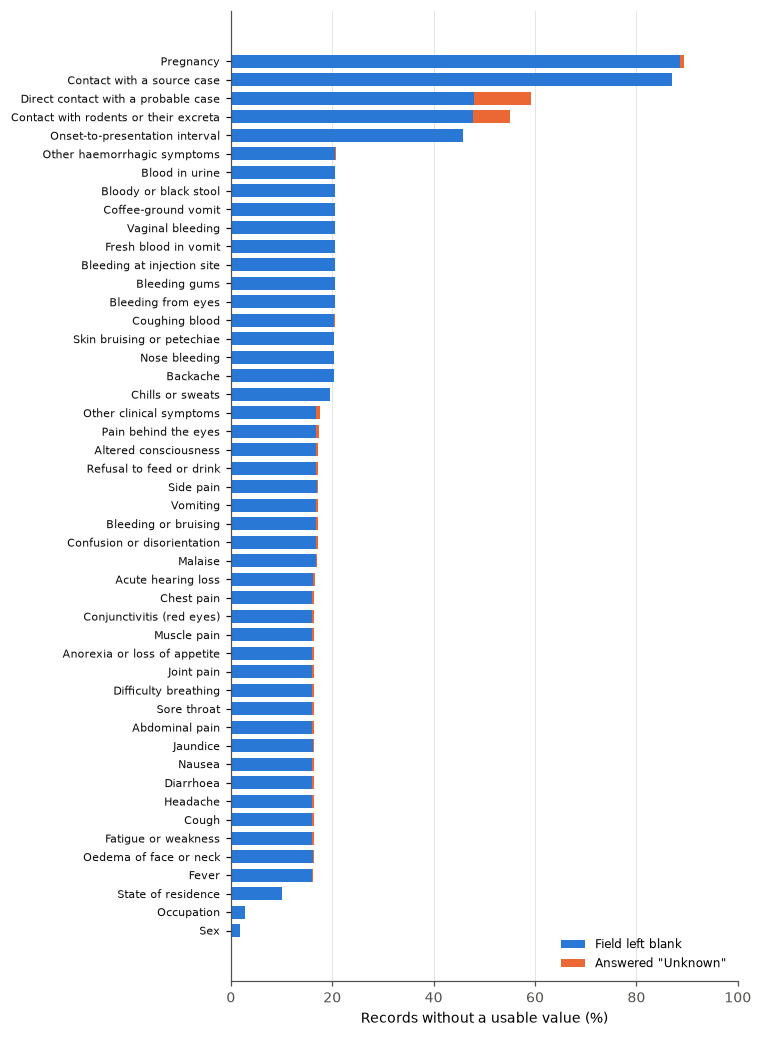

  saved figures/fig_missingness_by_predictor.png


In [10]:
miss = audit.set_index("label")["pct_unavailable"]
miss = miss[miss > 0].sort_values()
blank = audit.set_index("label")["pct_blank"].reindex(miss.index)
unk = audit.set_index("label")["pct_unknown"].reindex(miss.index)
fig, ax = plt.subplots(figsize=(7, 9.5))
ax.barh(miss.index, blank, color=BLUE, height=0.7, label="Field left blank")
ax.barh(miss.index, unk, left=blank, color=ORANGE, height=0.7, label='Answered "Unknown"')
ax.set_xlabel("Records without a usable value (%)"); ax.set_xlim(0, 100)
ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=7, colors=INK)
savefig("fig_missingness_by_predictor")

## 8. Cohort description (full analysed cohort)

In [11]:
def med_iqr(s):
    q = s.quantile([0.25, 0.5, 0.75])
    return f"{q[0.5]:.0f} ({q[0.25]:.0f}-{q[0.75]:.0f})"

groups = {"not_a_case": y == 0, "confirmed": y == 1}
rows = [{"characteristic": "n", **{g: int(m.sum()) for g, m in groups.items()}},
        {"characteristic": "Age, years, median (IQR)",
         **{g: med_iqr(X.loc[m, AGE_COL]) for g, m in groups.items()}},
        {"characteristic": "Age under 5 years, %",
         **{g: round(100 * (X.loc[m, AGE_COL] < 5).mean(), 1) for g, m in groups.items()}}]
for code_, name in SEX_NAMES.items():
    rows.append({"characteristic": f"Sex, {name}, n (%)",
                 **{g: f"{int((X.loc[m, SEX_COL] == code_).sum())} "
                       f"({100*(X.loc[m, SEX_COL] == code_).mean():.1f})" for g, m in groups.items()}})
rows.append({"characteristic": "Sex, not recorded, n (%)",
             **{g: f"{int(X.loc[m, SEX_COL].isna().sum())} ({100*X.loc[m, SEX_COL].isna().mean():.1f})"
                for g, m in groups.items()}})
rows.append({"characteristic": "Onset-to-presentation interval, days, median (IQR) [% unavailable]",
             **{g: f"{med_iqr(X.loc[m, 'onset_to_admission_days'].dropna())} "
                   f"[{100*X.loc[m, 'onset_to_admission_days'].isna().mean():.1f}]"
                for g, m in groups.items()}})
cohort = pd.DataFrame(rows)
save_table(cohort, "cohort_characteristics")
print(cohort.to_string(index=False))

prev = pd.DataFrame({
    "variable": bin_cols, "label": [LABELS[c] for c in bin_cols],
    "pct_yes_not_a_case": [100 * X.loc[y == 0, c].mean() for c in bin_cols],
    "pct_yes_confirmed": [100 * X.loc[y == 1, c].mean() for c in bin_cols],
    "pct_unavailable_not_a_case": [100 * X.loc[y == 0, c].isna().mean() for c in bin_cols],
    "pct_unavailable_confirmed": [100 * X.loc[y == 1, c].isna().mean() for c in bin_cols],
})
save_table(prev, "binary_predictor_prevalence_by_outcome")

  saved outputs/cohort_characteristics.csv  (7 rows)
                                                    characteristic     not_a_case       confirmed
                                                                 n          16865            3162
                                          Age, years, median (IQR)     29 (16-45)      32 (20-45)
                                              Age under 5 years, %           10.6             4.8
                                                Sex, female, n (%)    7918 (46.9)     1394 (44.1)
                                                  Sex, male, n (%)    8626 (51.1)     1724 (54.5)
                                          Sex, not recorded, n (%)      321 (1.9)        44 (1.4)
Onset-to-presentation interval, days, median (IQR) [% unavailable] 5 (2-8) [47.4] 6 (3-10) [36.8]


  saved outputs/binary_predictor_prevalence_by_outcome.csv  (45 rows)


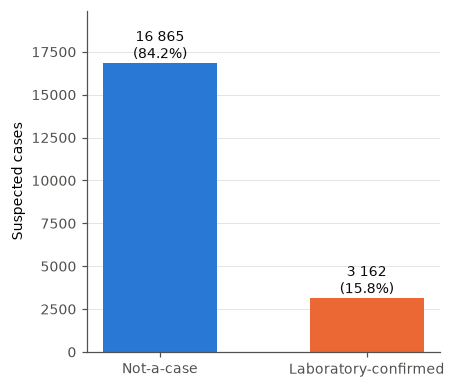

  saved figures/fig_class_distribution.png


In [12]:
counts = y.value_counts().reindex([0, 1])
fig, ax = plt.subplots(figsize=(4.2, 3.6))
bars = ax.bar(["Not-a-case", "Laboratory-confirmed"], counts.values, color=[BLUE, ORANGE], width=0.55)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{int(v):,}".replace(",", " ") + f"\n({100*v/counts.sum():.1f}%)",
            ha="center", va="bottom", color=INK)
ax.set_ylabel("Suspected cases"); ax.set_ylim(0, counts.max() * 1.18); ax.grid(axis="x", visible=False)
savefig("fig_class_distribution")

## 9. Descriptive association (training set only)

The ANOVA F statistic and mutual information describe how strongly each predictor is associated
with the outcome. They are computed on the training set only, with the imputer fitted on the
training set, so the held-out test set plays no part. They are descriptive and are not used for
feature selection; out-of-sample importance is estimated separately in section 15.

In [13]:
from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline as SkPipeline

def association_table(Xa, ya, fit_on=None):
    """F statistic, chi-square and mutual information; imputers fitted on `fit_on` (default Xa)."""
    ref = Xa if fit_on is None else fit_on
    num = pd.DataFrame(SimpleImputer(strategy="median").fit(ref[num_cols]).transform(Xa[num_cols]),
                       columns=num_cols)
    binary = pd.DataFrame(SimpleImputer(strategy="most_frequent").fit(ref[bin_cols])
                          .transform(Xa[bin_cols]), columns=bin_cols)
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False, max_categories=12)
    ohe.fit(ref[cat_cols].astype(str))
    cat = pd.DataFrame(ohe.transform(Xa[cat_cols].astype(str)),
                       columns=ohe.get_feature_names_out(cat_cols))
    Xr = pd.concat([num, binary, cat], axis=1)
    F, _ = f_classif(Xr, ya)
    discrete = np.array([c not in num_cols for c in Xr.columns])
    mi = mutual_info_classif(Xr, ya, discrete_features=discrete, random_state=RANDOM_STATE)
    chi2 = []
    for c in Xr.columns:
        if c in num_cols:
            chi2.append(np.nan); continue
        table = pd.crosstab(Xr[c].values, np.asarray(ya))
        chi2.append(stats.chi2_contingency(table, correction=False)[0] if table.shape == (2, 2)
                    else np.nan)
    kind = ["numeric" if c in num_cols else ("binary" if c in bin_cols else "categorical level")
            for c in Xr.columns]
    return (pd.DataFrame({"feature": Xr.columns, "kind": kind, "anova_F": F, "chi_square": chi2,
                          "mutual_info": mi})
            .sort_values("anova_F", ascending=False).reset_index(drop=True))

assoc = association_table(X_tr, y_tr)
assoc["label"] = [LABELS.get(f, f) for f in assoc["feature"]]
assoc["rank_F"] = assoc["anova_F"].rank(ascending=False).astype(int)
assoc["rank_MI"] = assoc["mutual_info"].rank(ascending=False).astype(int)
save_table(assoc, "association_training_set")
print(assoc.head(20)[["label", "kind", "anova_F", "chi_square", "mutual_info", "rank_MI"]]
      .round(4).to_string(index=False))

b = assoc[assoc["kind"] == "binary"]
rho_chi = stats.spearmanr(b["anova_F"], b["chi_square"])[0]
rho_mi = stats.spearmanr(assoc["anova_F"], assoc["mutual_info"])[0]
top_F = set(assoc.nlargest(15, "anova_F")["feature"]); top_MI = set(assoc.nlargest(15, "mutual_info")["feature"])
assoc_full = association_table(X, y)
merged = assoc.merge(assoc_full, on="feature", suffixes=("_train", "_full"))
rho_full = stats.spearmanr(merged["anova_F_train"], merged["anova_F_full"])[0]
assoc_summary = pd.DataFrame([{
    "n_training": len(y_tr), "spearman_F_vs_chi_square_binary": rho_chi,
    "spearman_F_vs_mutual_info": rho_mi, "top15_shared_F_and_MI": len(top_F & top_MI),
    "numeric_in_top15_F": int(assoc.head(15)["kind"].eq("numeric").sum()),
    "spearman_F_training_vs_full_cohort": rho_full,
    "top15_shared_training_and_full_cohort": len(top_F & set(assoc_full.nlargest(15, "anova_F")["feature"])),
}])
save_table(assoc_summary, "association_summary")
print(assoc_summary.round(3).T.to_string(header=False))

  saved outputs/association_training_set.csv  (78 rows)
                       label   kind  anova_F  chi_square  mutual_info  rank_MI
         Fatigue or weakness binary 589.0072    568.1888       0.0155        1
                    Vomiting binary 566.6181    547.3290       0.0145        2
Anorexia or loss of appetite binary 451.9701    439.6227       0.0111        3
                  Chest pain binary 371.9103    363.5170       0.0090        6
              Abdominal pain binary 345.4904    338.2386       0.0096        5
                     Malaise binary 333.1434    326.3970       0.0075        8
                 Muscle pain binary 306.9724    301.2381       0.0071        9
                      Nausea binary 209.4044    206.7281       0.0052       12
                   Diarrhoea binary 188.1811    186.0194       0.0049       13
    Refusal to feed or drink binary 182.7328    180.6944       0.0042       14
                    Headache binary 179.4544    177.4885       0.0054      

  saved outputs/association_summary.csv  (1 rows)
n_training                             16021.000
spearman_F_vs_chi_square_binary            1.000
spearman_F_vs_mutual_info                  0.978
top15_shared_F_and_MI                     13.000
numeric_in_top15_F                         0.000
spearman_F_training_vs_full_cohort         0.990
top15_shared_training_and_full_cohort     15.000


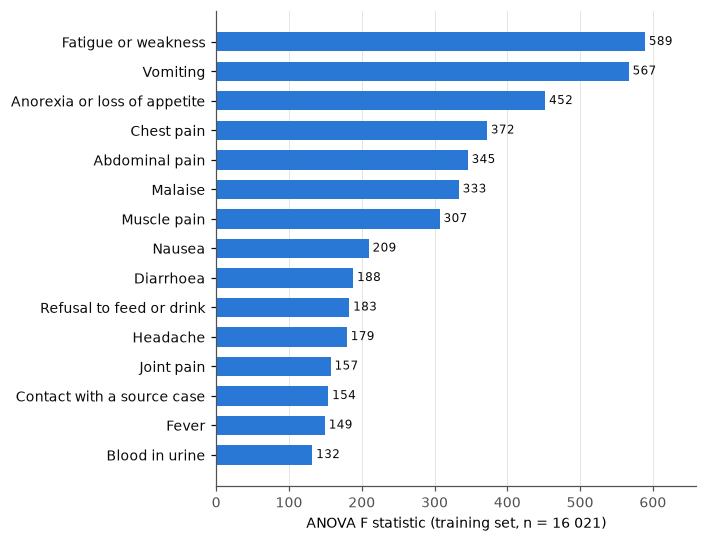

  saved figures/fig_association_top15.png


In [14]:
top = assoc.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(top["label"], top["anova_F"], color=BLUE, height=0.65)
for v, lab in zip(top["anova_F"], top["label"]):
    ax.text(v, lab, f" {v:.0f}", va="center", ha="left", color=INK, fontsize=8)
ax.set_xlabel("ANOVA F statistic (training set, n = %s)" % f"{len(y_tr):,}".replace(",", " "))
ax.set_xlim(0, top["anova_F"].max() * 1.12); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK)
savefig("fig_association_top15")

## 10. Models and pipeline

All preprocessing and SMOTE sit inside one pipeline, so they are fitted on training folds only.
No hyperparameter search was run; the values below were fixed in advance.

In [15]:
import xgboost as xgb
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              VotingClassifier, StackingClassifier)

def make_preprocessor(num, binary, cat, passthrough=()):
    num, binary, cat, passthrough = list(num), list(binary), list(cat), list(passthrough)
    parts = []
    if num:
        parts.append(("num", SkPipeline([("imp", SimpleImputer(strategy="median")),
                                         ("sc", StandardScaler())]), list(num)))
    if binary:
        parts.append(("bin", SimpleImputer(strategy="most_frequent"), list(binary)))
    if cat:
        parts.append(("cat", SkPipeline([("imp", SimpleImputer(strategy="most_frequent")),
                                         ("ohe", OneHotEncoder(handle_unknown="ignore",
                                                               max_categories=12))]), list(cat)))
    if passthrough:
        parts.append(("ind", "passthrough", list(passthrough)))
    return ColumnTransformer(parts, remainder="drop")

preprocessor = make_preprocessor(num_cols, bin_cols, cat_cols)

def make_pipe(est, pre=None):
    return ImbPipeline([("pre", clone(preprocessor if pre is None else pre)),
                        ("smote", SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),
                        ("clf", clone(est))])

def xgb_clf():
    return xgb.XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.9,
                             colsample_bytree=0.9, eval_metric="logloss", tree_method="hist",
                             device="cpu", n_jobs=N_JOBS, random_state=RANDOM_STATE)

base_models = {
    "LogReg": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "SVM(LinearSVC)": CalibratedClassifierCV(LinearSVC(random_state=RANDOM_STATE, dual="auto"), cv=3),
    "KNN": KNeighborsClassifier(n_neighbors=5, n_jobs=N_JOBS),
    "MLP": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True,
                         random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=RANDOM_STATE),
    "HistGB": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
    "XGBoost": xgb_clf(),
}
soft_vote = VotingClassifier(
    [("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
     ("rf", RandomForestClassifier(n_estimators=300, n_jobs=N_JOBS, random_state=RANDOM_STATE)),
     ("xgb", xgb_clf())], voting="soft")
stack = StackingClassifier(
    [("rf", RandomForestClassifier(n_estimators=200, n_jobs=N_JOBS, random_state=RANDOM_STATE)),
     ("xgb", xgb_clf()),
     ("lr", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))],
    final_estimator=LogisticRegression(max_iter=1000), cv=3, n_jobs=N_JOBS)
all_models = {**base_models, "SoftVote(LR+RF+XGB)": soft_vote, "Stacking(RF+XGB+LR)": stack}

MODEL_NAMES = {"LogReg": "Logistic regression", "SVM(LinearSVC)": "Linear SVM",
               "KNN": "k-nearest neighbours", "MLP": "Multilayer perceptron",
               "RandomForest": "Random forest", "HistGB": "Histogram gradient boosting",
               "XGBoost": "XGBoost", "SoftVote(LR+RF+XGB)": "Soft voting",
               "Stacking(RF+XGB+LR)": "Stacking"}

In [16]:
# Hyperparameter record: every value, including library defaults, read from the estimators
def params_of(est, keys):
    p = est.get_params(deep=False)
    return "; ".join(f"{k}={p[k]}" for k in keys)

# scikit-learn >= 1.8 expresses the penalty through l1_ratio (0 = L2); older versions use `penalty`
lr_params = all_models["LogReg"].get_params()
lr_keys = [k for k in ["C", "solver", "max_iter", "tol", "fit_intercept", "class_weight"] if k in lr_params]
lr_is_l2 = lr_params.get("penalty") == "l2" or lr_params.get("l1_ratio") in (0, 0.0)
assert lr_is_l2, "logistic regression is expected to use the L2 penalty"
rf_keys = ["n_estimators", "criterion", "max_depth", "max_features", "min_samples_split",
           "min_samples_leaf", "bootstrap", "class_weight"]
xgb_keys = ["n_estimators", "max_depth", "learning_rate", "subsample", "colsample_bytree",
            "tree_method", "device", "eval_metric"]
xgb_defaults = ("objective=binary:logistic; min_child_weight=1; gamma=0; reg_lambda=1; "
                "reg_alpha=0; max_bin=256")
hp = [
    ("Preprocessing", "numeric: median imputation, z-score standardisation; binary: mode "
     "imputation; categorical: mode imputation, one-hot encoding with max_categories=12 and "
     "handle_unknown=ignore"),
    ("Class-imbalance correction", "SMOTE; " + params_of(SMOTE(random_state=RANDOM_STATE, k_neighbors=5),
                                                       ["sampling_strategy", "k_neighbors"])
     + "; applied inside training folds only"),
    ("Logistic regression", "penalty=l2; " + params_of(all_models["LogReg"], lr_keys)),
    ("Linear SVM", "LinearSVC: " + params_of(LinearSVC(random_state=RANDOM_STATE, dual="auto"),
                                             ["C", "loss", "penalty", "dual", "tol", "max_iter"])
     + "; probabilities: CalibratedClassifierCV, "
     + params_of(all_models["SVM(LinearSVC)"], ["method", "cv"])),
    ("k-nearest neighbours", params_of(all_models["KNN"], ["n_neighbors", "weights", "metric", "p",
                                                           "algorithm"])),
    ("Multilayer perceptron", params_of(all_models["MLP"], [
        "hidden_layer_sizes", "activation", "solver", "alpha", "batch_size", "learning_rate_init",
        "max_iter", "early_stopping", "validation_fraction", "n_iter_no_change", "tol"])),
    ("Random forest", params_of(all_models["RandomForest"], rf_keys)),
    ("Histogram gradient boosting", params_of(all_models["HistGB"], [
        "loss", "learning_rate", "max_iter", "max_leaf_nodes", "max_depth", "min_samples_leaf",
        "l2_regularization", "max_bins", "early_stopping", "validation_fraction",
        "n_iter_no_change"])),
    ("XGBoost", params_of(xgb_clf(), xgb_keys) + "; library defaults: " + xgb_defaults),
    ("Soft voting", "members: logistic regression, random forest (300 trees), XGBoost, each "
     "configured as above; voting=soft; equal weights"),
    ("Stacking", "base learners: random forest (n_estimators=200, otherwise as above), XGBoost, "
     "logistic regression; meta-learner: logistic regression (max_iter=1000) on base-learner "
     "probabilities; " + params_of(stack, ["cv", "stack_method", "passthrough"])),
    ("All models", f"random_state={RANDOM_STATE}; decision threshold 0.5 unless stated; no "
     "hyperparameter search"),
]
hyper = pd.DataFrame(hp, columns=["component", "hyperparameters"])
save_table(hyper, "hyperparameters")
for comp, text in hp:
    print(f"- {comp}: {text}")

def jsonable(v):
    return v if isinstance(v, (int, float, str, bool, type(None))) else str(v)
full_params = {MODEL_NAMES[k]: {p: jsonable(v) for p, v in est.get_params(deep=True).items()}
               for k, est in all_models.items()}
(OUT_DIR / "hyperparameters_full.json").write_text(json.dumps(full_params, indent=1))

import sklearn, imblearn, shap
env = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
       "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__,
       "xgboost": xgb.__version__, "shap": shap.__version__, "pyreadstat": pyreadstat.__version__,
       "matplotlib": mpl.__version__, "platform": platform.platform()}
(OUT_DIR / "environment.json").write_text(json.dumps(env, indent=1))
print("\n", env)

  saved outputs/hyperparameters.csv  (12 rows)
- Preprocessing: numeric: median imputation, z-score standardisation; binary: mode imputation; categorical: mode imputation, one-hot encoding with max_categories=12 and handle_unknown=ignore
- Class-imbalance correction: SMOTE; sampling_strategy=auto; k_neighbors=5; applied inside training folds only
- Logistic regression: penalty=l2; C=1.0; solver=lbfgs; max_iter=2000; tol=0.0001; fit_intercept=True; class_weight=None
- Linear SVM: LinearSVC: C=1.0; loss=squared_hinge; penalty=l2; dual=auto; tol=0.0001; max_iter=1000; probabilities: CalibratedClassifierCV, method=sigmoid; cv=3
- k-nearest neighbours: n_neighbors=5; weights=uniform; metric=minkowski; p=2; algorithm=auto
- Multilayer perceptron: hidden_layer_sizes=(64, 32); activation=relu; solver=adam; alpha=0.0001; batch_size=auto; learning_rate_init=0.001; max_iter=300; early_stopping=True; validation_fraction=0.1; n_iter_no_change=10; tol=0.0001
- Random forest: n_estimators=300; criter


 {'python': '3.14.2', 'numpy': '2.4.2', 'pandas': '3.0.1', 'scikit-learn': '1.9.0', 'imbalanced-learn': '0.14.2', 'xgboost': '3.3.0', 'shap': '0.52.0', 'pyreadstat': '1.3.6', 'matplotlib': '3.11.0', 'platform': 'Windows-10-10.0.19045-SP0'}


## 11. Cross-validation (training set)

Stratified five-fold cross-validation. Intervals are t-based 95% confidence intervals across the
five folds, mean ± t(0.975, 4) · SD / √5.

In [17]:
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, brier_score_loss)

SCORING = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy",
           "precision": "precision", "recall": "recall", "f1": "f1",
           "roc_auc": "roc_auc", "pr_auc": "average_precision"}
T_CRIT = stats.t.ppf(0.975, cv.get_n_splits() - 1)

def cv_evaluate(models, Xa, ya, pre=None, verbose=True):
    summary, folds = [], []
    for name, est in models.items():
        res = cross_validate(make_pipe(est, pre), Xa, ya, cv=cv, scoring=SCORING, n_jobs=N_JOBS)
        row = {"model": name}
        for m in SCORING:
            v = res[f"test_{m}"]
            row[m] = v.mean(); row[m + "_sd"] = v.std(ddof=1)
            row[m + "_ci95"] = T_CRIT * v.std(ddof=1) / np.sqrt(len(v))
            folds += [{"model": name, "metric": m, "fold": i + 1, "value": x} for i, x in enumerate(v)]
        summary.append(row)
        if verbose:
            print(f"  CV {name:22s} F1={row['f1']:.3f}  bal.acc={row['balanced_accuracy']:.3f}  "
                  f"ROC-AUC={row['roc_auc']:.3f}")
    return pd.DataFrame(summary), pd.DataFrame(folds)

cv_df, cv_folds = cv_evaluate(all_models, X_tr, y_tr)
cv_df = cv_df.sort_values("balanced_accuracy", ascending=False).reset_index(drop=True)
save_table(cv_df, "cv_results"); save_table(cv_folds, "cv_fold_scores")
print("\n", cv_df[["model"] + list(SCORING)].round(3).to_string(index=False))

# Model selection rule, fixed before the test set is touched: highest cross-validated F1
best_name = cv_df.sort_values("f1", ascending=False).iloc[0]["model"]
print(f"\nSelected model (highest cross-validated F1): {best_name}; "
      f"highest balanced accuracy: {cv_df.iloc[0]['model']}; "
      f"highest ROC-AUC: {cv_df.sort_values('roc_auc', ascending=False).iloc[0]['model']}")

  CV LogReg                 F1=0.377  bal.acc=0.652  ROC-AUC=0.704


  CV SVM(LinearSVC)         F1=0.375  bal.acc=0.650  ROC-AUC=0.702


  CV KNN                    F1=0.330  bal.acc=0.607  ROC-AUC=0.633


  CV MLP                    F1=0.304  bal.acc=0.586  ROC-AUC=0.608


  CV RandomForest           F1=0.275  bal.acc=0.575  ROC-AUC=0.691


  CV HistGB                 F1=0.305  bal.acc=0.590  ROC-AUC=0.703


  CV XGBoost                F1=0.268  bal.acc=0.575  ROC-AUC=0.698


  CV SoftVote(LR+RF+XGB)    F1=0.358  bal.acc=0.614  ROC-AUC=0.719


  CV Stacking(RF+XGB+LR)    F1=0.304  bal.acc=0.588  ROC-AUC=0.703
  saved outputs/cv_results.csv  (9 rows)
  saved outputs/cv_fold_scores.csv  (315 rows)

               model  accuracy  balanced_accuracy  precision  recall    f1  roc_auc  pr_auc
             LogReg     0.688              0.652      0.276   0.599 0.377    0.704   0.354
     SVM(LinearSVC)     0.685              0.650      0.273   0.600 0.375    0.702   0.351
SoftVote(LR+RF+XGB)     0.830              0.614      0.445   0.299 0.358    0.719   0.384
                KNN     0.681              0.607      0.247   0.499 0.330    0.633   0.239
             HistGB     0.845              0.590      0.523   0.216 0.305    0.703   0.363
Stacking(RF+XGB+LR)     0.815              0.588      0.375   0.256 0.304    0.703   0.305
                MLP     0.743              0.586      0.268   0.357 0.304    0.608   0.285
            XGBoost     0.848              0.575      0.555   0.177 0.268    0.698   0.363
       RandomForest     

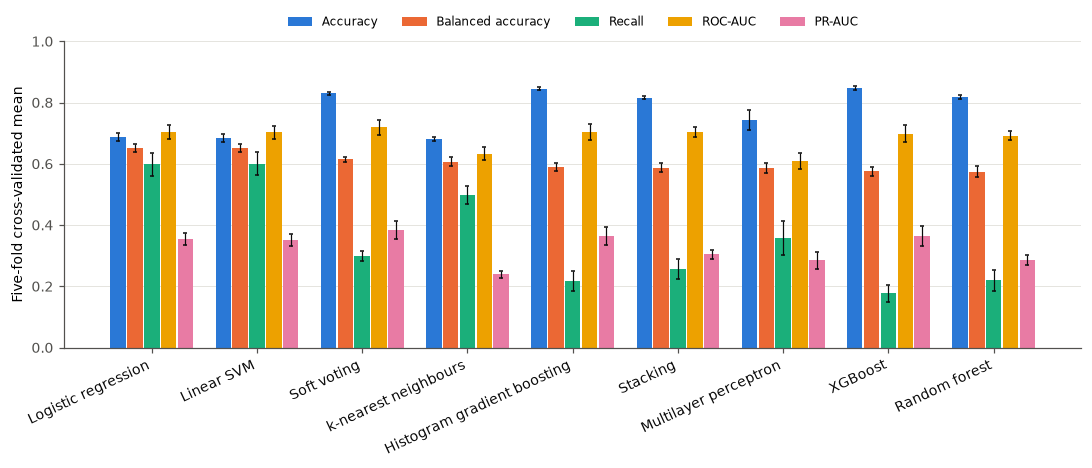

  saved figures/fig_cv_model_comparison.png


In [18]:
metrics_shown = [("accuracy", "Accuracy", BLUE), ("balanced_accuracy", "Balanced accuracy", ORANGE),
                 ("recall", "Recall", AQUA), ("roc_auc", "ROC-AUC", YELLOW), ("pr_auc", "PR-AUC", MAGENTA)]
fig, ax = plt.subplots(figsize=(10, 4.4))
xpos = np.arange(len(cv_df)); w = 0.16
for i, (m, lab, col) in enumerate(metrics_shown):
    ax.bar(xpos + (i - 2) * w, cv_df[m], w * 0.92, yerr=cv_df[m + "_ci95"], color=col, label=lab,
           error_kw={"elinewidth": 0.8, "capsize": 1.5, "ecolor": INK})
ax.set_xticks(xpos); ax.set_xticklabels([MODEL_NAMES[m] for m in cv_df["model"]], rotation=25, ha="right",
                                        color=INK)
ax.set_ylim(0, 1); ax.set_ylabel("Five-fold cross-validated mean"); ax.grid(axis="x", visible=False)
ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.12))
savefig("fig_cv_model_comparison")

## 12. Held-out test set: all nine models

Each model is refitted on the whole training set and evaluated once on the test set. Threshold
metrics use the default threshold of 0.5. Confidence intervals come from 2000 bootstrap resamples
of the test set; differences from the selected model use the same resamples (paired bootstrap).

In [19]:
def fit_all(models, Xa, ya, pre=None):
    return {name: make_pipe(est, pre).fit(Xa, ya) for name, est in models.items()}

def proba(p, Xv):
    return p.predict_proba(Xv)[:, 1]

def threshold_metrics(yt, pp, thr=0.5):
    yt = np.asarray(yt); pred = np.asarray(pp) >= thr
    tp = int((pred & (yt == 1)).sum()); fp = int((pred & (yt == 0)).sum())
    fn = int((~pred & (yt == 1)).sum()); tn = int((~pred & (yt == 0)).sum())
    rec = tp / (tp + fn) if tp + fn else 0.0; spec = tn / (tn + fp) if tn + fp else 0.0
    prec = tp / (tp + fp) if tp + fp else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"tp": tp, "fp": fp, "fn": fn, "tn": tn, "accuracy": (tp + tn) / len(yt),
            "balanced_accuracy": (rec + spec) / 2, "precision": prec, "recall": rec,
            "specificity": spec, "f1": f1}

def all_metrics(yt, pp, thr=0.5):
    return {**threshold_metrics(yt, pp, thr), "roc_auc": roc_auc_score(yt, pp),
            "average_precision": average_precision_score(yt, pp),
            "brier": brier_score_loss(yt, pp), "mean_predicted_probability": float(np.mean(pp))}

fitted = fit_all(all_models, X_tr, y_tr)
P_te = pd.DataFrame({name: proba(p, X_te) for name, p in fitted.items()}, index=X_te.index)
P_te.assign(y=y_te).to_csv(OUT_DIR / "test_predictions.csv", index=False)

CI_METRICS = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1",
              "roc_auc", "average_precision", "brier"]
rng = np.random.default_rng(RANDOM_STATE)
yt_arr = y_te.to_numpy()
boot_idx = [i for i in (rng.integers(0, len(yt_arr), len(yt_arr)) for _ in range(N_BOOT))
            if 0 < yt_arr[i].sum() < len(i)]

def bootstrap(pp, thr=0.5):
    pp = np.asarray(pp)
    return pd.DataFrame([{k: v for k, v in all_metrics(yt_arr[i], pp[i], thr).items()
                          if k in CI_METRICS} for i in boot_idx])

boot = {name: bootstrap(P_te[name]) for name in all_models}
rows = []
for name in cv_df["model"]:
    m = all_metrics(yt_arr, P_te[name].to_numpy()); row = {"model": name, **m}
    for k in CI_METRICS:
        row[k + "_lo"], row[k + "_hi"] = np.percentile(boot[name][k], [2.5, 97.5])
    rows.append(row)
test_df = pd.DataFrame(rows)
save_table(test_df, "test_results")
print(test_df[["model", "tp", "fp", "fn", "tn"] + CI_METRICS].round(3).to_string(index=False))

rows = []
for name in cv_df["model"]:
    if name == best_name:
        continue
    row = {"model": name, "reference": best_name}
    for k in ["roc_auc", "average_precision", "balanced_accuracy", "f1", "recall"]:
        diff = boot[name][k] - boot[best_name][k]
        row[k + "_diff"] = test_df.set_index("model").loc[name, k] - test_df.set_index("model").loc[best_name, k]
        row[k + "_diff_lo"], row[k + "_diff_hi"] = np.percentile(diff, [2.5, 97.5])
    rows.append(row)
test_diff = pd.DataFrame(rows)
save_table(test_diff, "test_differences_vs_selected_model")
print("\nDifference from", best_name, "(paired bootstrap 95% CI):")
print(test_diff.round(3).to_string(index=False))

  saved outputs/test_results.csv  (9 rows)
              model  tp   fp  fn   tn  accuracy  balanced_accuracy  precision  recall  specificity    f1  roc_auc  average_precision  brier
             LogReg 364 1003 268 2371     0.683              0.639      0.266   0.576        0.703 0.364    0.699              0.359  0.212
     SVM(LinearSVC) 367 1005 265 2369     0.683              0.641      0.267   0.581        0.702 0.366    0.698              0.359  0.213
SoftVote(LR+RF+XGB) 178  219 454 3155     0.832              0.608      0.448   0.282        0.935 0.346    0.709              0.376  0.140
                KNN 297  936 335 2438     0.683              0.596      0.241   0.470        0.723 0.318    0.622              0.225  0.231
             HistGB 112  101 520 3273     0.845              0.574      0.526   0.177        0.970 0.265    0.692              0.357  0.131
Stacking(RF+XGB+LR) 168  290 464 3084     0.812              0.590      0.367   0.266        0.914 0.308    0.695    

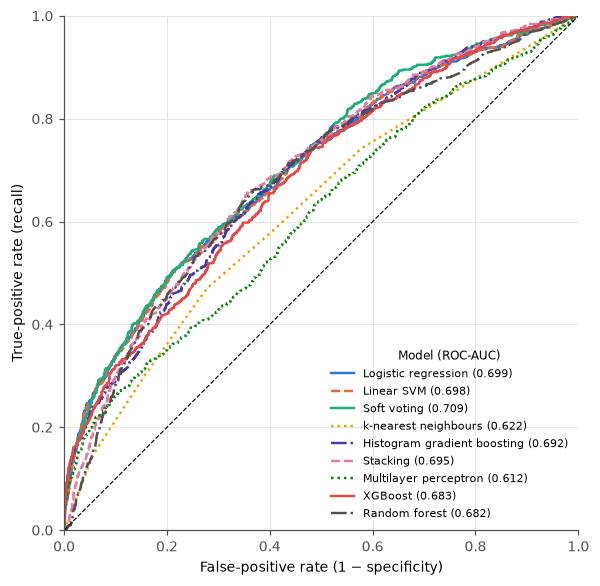

  saved figures/fig_roc_test.png


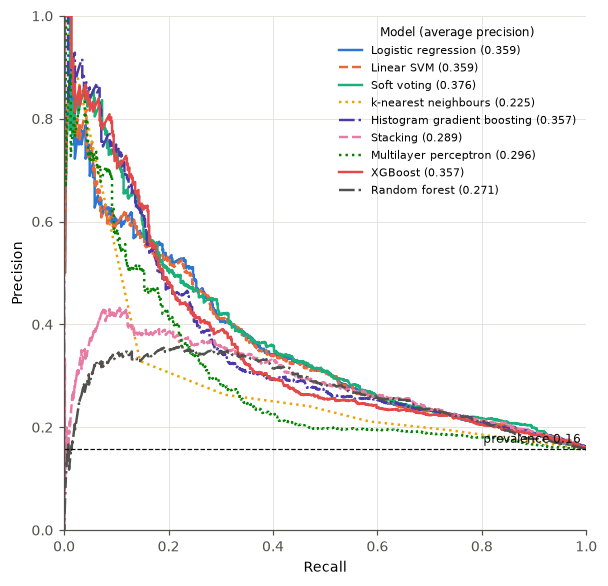

  saved figures/fig_pr_test.png


In [20]:
STYLE = {"LogReg": (BLUE, "-"), "SVM(LinearSVC)": (ORANGE, "--"), "SoftVote(LR+RF+XGB)": (AQUA, "-"),
         "KNN": (YELLOW, ":"), "Stacking(RF+XGB+LR)": (MAGENTA, "--"), "MLP": (GREEN, ":"),
         "HistGB": (VIOLET, "-."), "XGBoost": (RED, "-"), "RandomForest": (MUTED, "-.")}

fig, ax = plt.subplots(figsize=(5.6, 5.4))
for name in cv_df["model"]:
    fpr, tpr, _ = roc_curve(y_te, P_te[name]); col, ls = STYLE[name]
    ax.plot(fpr, tpr, color=col, ls=ls, lw=1.6,
            label=f"{MODEL_NAMES[name]} ({roc_auc_score(y_te, P_te[name]):.3f})")
ax.plot([0, 1], [0, 1], color=INK, ls="--", lw=0.8)
ax.set_xlabel("False-positive rate (1 − specificity)"); ax.set_ylabel("True-positive rate (recall)")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.legend(title="Model (ROC-AUC)", loc="lower right", fontsize=7.5, title_fontsize=8)
savefig("fig_roc_test")

fig, ax = plt.subplots(figsize=(5.6, 5.4))
for name in cv_df["model"]:
    pr, rc, _ = precision_recall_curve(y_te, P_te[name]); col, ls = STYLE[name]
    ax.plot(rc, pr, color=col, ls=ls, lw=1.6,
            label=f"{MODEL_NAMES[name]} ({average_precision_score(y_te, P_te[name]):.3f})")
ax.axhline(y_te.mean(), color=INK, ls="--", lw=0.8)
ax.text(0.99, y_te.mean() + 0.012, f"prevalence {y_te.mean():.2f}", ha="right", color=INK, fontsize=8)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(title="Model (average precision)", loc="upper right", fontsize=7.5, title_fontsize=8)
savefig("fig_pr_test")

## 13. Calibration and decision threshold of the selected model

The alternative threshold is the one that maximises F1 on out-of-fold predictions within the
training set. It is then applied unchanged to the test set, so the test set is not used to choose it.

In [21]:
best = fitted[best_name]; yp_best = P_te[best_name].to_numpy()
obs, pred_mean = calibration_curve(y_te, yp_best, n_bins=10, strategy="quantile")
z = np.log(np.clip(yp_best, 1e-6, 1 - 1e-6) / (1 - np.clip(yp_best, 1e-6, 1 - 1e-6)))
recal = LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y_te)
cal_slope = recal.coef_[0, 0]

oof = cross_val_predict(make_pipe(all_models[best_name]), X_tr, y_tr, cv=cv,
                        method="predict_proba", n_jobs=N_JOBS)[:, 1]
pr_o, rc_o, thr_o = precision_recall_curve(y_tr, oof)
f1_o = 2 * pr_o * rc_o / (pr_o + rc_o + 1e-12)
THR_CV = float(thr_o[int(np.nanargmax(f1_o[:-1]))])

pr_t, rc_t, thr_t = precision_recall_curve(y_te, yp_best)
f1_t = 2 * pr_t * rc_t / (pr_t + rc_t + 1e-12)
thr_test_max = float(thr_t[int(np.nanargmax(f1_t[:-1]))])

rows = []
for label, thr in [("default", 0.5), ("F1-maximising in cross-validation", THR_CV)]:
    m = threshold_metrics(yt_arr, yp_best, thr); b = bootstrap(yp_best, thr)
    row = {"threshold_rule": label, "threshold": thr, **m}
    for k in ["precision", "recall", "specificity", "f1", "balanced_accuracy"]:
        row[k + "_lo"], row[k + "_hi"] = np.percentile(b[k], [2.5, 97.5])
    rows.append(row)
thr_df = pd.DataFrame(rows)
save_table(thr_df, "threshold_analysis_selected_model")
print(thr_df.round(3).T.to_string(header=False))

calib = pd.DataFrame([{
    "model": best_name, "brier": brier_score_loss(y_te, yp_best),
    "mean_predicted_probability": yp_best.mean(), "observed_prevalence": y_te.mean(),
    "calibration_slope": cal_slope, "f1_max_threshold_cv": THR_CV,
    "f1_max_threshold_test_for_reference": thr_test_max,
    "out_of_fold_f1_at_cv_threshold": float(np.nanmax(f1_o[:-1]))}])
save_table(calib, "calibration_selected_model")
save_table(pd.DataFrame({"mean_predicted": pred_mean, "observed_fraction": obs}), "calibration_curve_bins")
print(calib.round(3).T.to_string(header=False))

  saved outputs/threshold_analysis_selected_model.csv  (2 rows)
threshold_rule        default  F1-maximising in cross-validation
threshold                 0.5                              0.546
tp                        364                                312
fp                       1003                                684
fn                        268                                320
tn                       2371                               2690
accuracy                0.683                              0.749
balanced_accuracy       0.639                              0.645
precision               0.266                              0.313
recall                  0.576                              0.494
specificity             0.703                              0.797
f1                      0.364                              0.383
precision_lo            0.243                              0.284
precision_hi            0.289                              0.341
recall_lo               0.

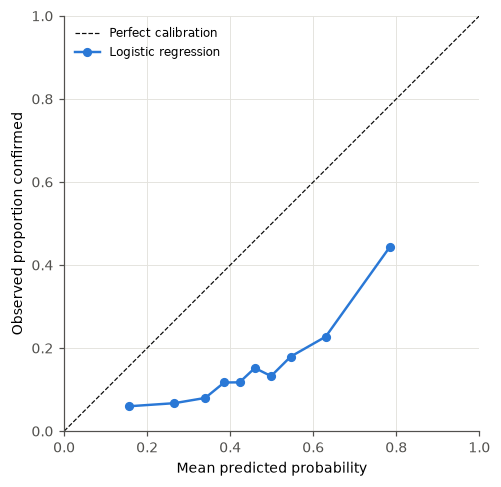

  saved figures/fig_calibration_selected_model.png


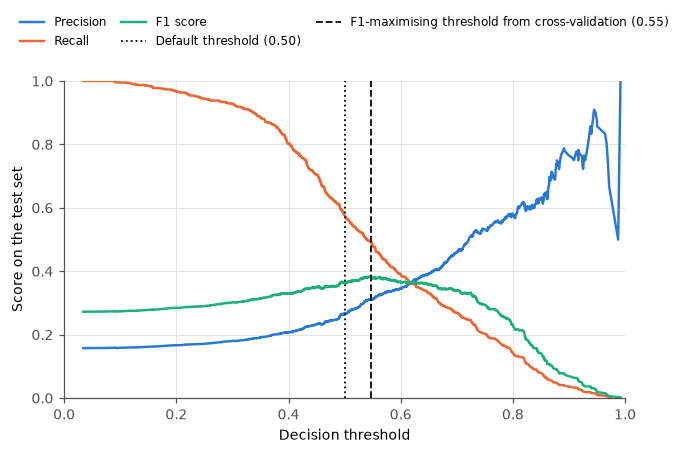

  saved figures/fig_threshold_selected_model.png


In [22]:
fig, ax = plt.subplots(figsize=(4.6, 4.5))
ax.plot([0, 1], [0, 1], color=INK, ls="--", lw=0.8, label="Perfect calibration")
ax.plot(pred_mean, obs, "o-", color=BLUE, lw=1.6, ms=5, label=MODEL_NAMES[best_name])
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed proportion confirmed")
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal"); ax.legend(loc="upper left")
savefig("fig_calibration_selected_model")

fig, ax = plt.subplots(figsize=(6.4, 4.3))
ax.plot(thr_t, pr_t[:-1], color=BLUE, lw=1.6, label="Precision")
ax.plot(thr_t, rc_t[:-1], color=ORANGE, lw=1.6, label="Recall")
ax.plot(thr_t, f1_t[:-1], color=AQUA, lw=1.6, label="F1 score")
ax.axvline(0.5, color=INK, ls=":", lw=1.2, label="Default threshold (0.50)")
ax.axvline(THR_CV, color=INK, ls="--", lw=1.2,
           label=f"F1-maximising threshold from cross-validation ({THR_CV:.2f})")
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score on the test set")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.24), ncol=3, columnspacing=1.2)
savefig("fig_threshold_selected_model")

## 14. Explanation of the logistic regression

Coefficients and SHAP values are computed for the logistic regression itself, the model selected
in section 11. For a linear model
the SHAP value of feature j is β_j (x_j − mean_j) on the log-odds scale; the background is the
preprocessed training set at its real prevalence. One-hot columns are also summed back to their
source variable so that every predictor is ranked once; the two dummy columns of a two-level
variable such as sex are collinear, and only their sum is meaningful.

In [23]:
import shap

def to_dense(a):
    return a.toarray() if hasattr(a, "toarray") else np.asarray(a)

lr_pipe = fitted["LogReg"]
if best_name != "LogReg":
    print("Note: the selected model is", best_name, "- this section explains the logistic regression.")
pre_lr = lr_pipe.named_steps["pre"]; clf_lr = lr_pipe.named_steps["clf"]
feat_names = list(pre_lr.get_feature_names_out())
Xtr_tx = to_dense(pre_lr.transform(X_tr)); Xte_tx = to_dense(pre_lr.transform(X_te))

coef = pd.DataFrame({"feature": feat_names, "label": [pretty(f) for f in feat_names],
                     "variable": [original_variable(f) for f in feat_names],
                     "coefficient": clf_lr.coef_[0]})
# One-hot levels are coded without a reference level, so only differences between the levels of
# a variable are identified: centre them on the mean of the variable's levels before reading them
is_cat = coef["variable"].isin(cat_cols)
coef["coefficient_centred"] = coef["coefficient"] - np.where(
    is_cat, coef.groupby("variable")["coefficient"].transform("mean"), 0.0)
coef["odds_ratio"] = np.exp(coef["coefficient_centred"])
coef["scale"] = np.where(coef["feature"].str.startswith("num__"), "per 1 SD increase",
                         np.where(is_cat, "level vs average level", "yes vs no"))
coef = coef.reindex(coef["coefficient_centred"].abs().sort_values(ascending=False).index).reset_index(drop=True)
save_table(coef, "logistic_regression_coefficients")
print(f"Intercept: {clf_lr.intercept_[0]:.3f}")
print(coef.head(20)[["label", "coefficient_centred", "odds_ratio", "scale"]].round(3).to_string(index=False))

background = shap.maskers.Independent(Xtr_tx, max_samples=len(Xtr_tx))   # whole training set
explainer = shap.LinearExplainer(clf_lr, background)
sv_lr = np.asarray(explainer.shap_values(Xte_tx))
closed_form = clf_lr.coef_[0] * (Xte_tx - Xtr_tx.mean(axis=0))
assert np.allclose(sv_lr, closed_form, atol=1e-6), "SHAP values differ from the closed form"

def by_variable(sv, Xtx, names):
    """Sum SHAP values over the one-hot columns of each source variable.

    Returns the per-variable SHAP matrix and a matching matrix of the values the model saw
    (after imputation; NaN for categorical variables, which have no single ordering)."""
    variables = [original_variable(n) for n in names]
    S = pd.DataFrame(sv, columns=names).T.groupby(variables).sum().T
    V = pd.DataFrame(np.nan, index=S.index, columns=S.columns)
    for j, v in enumerate(variables):
        if v not in cat_cols:
            V[v] = Xtx[:, j]
    return S, V

def aggregate_shap(S):
    frame = pd.DataFrame({"mean_abs_shap": S.abs().mean()})
    frame["label"] = [LABELS[v] for v in frame.index]
    return frame.sort_values("mean_abs_shap", ascending=False).rename_axis("variable").reset_index()

S_lr, V_lr = by_variable(sv_lr, Xte_tx, feat_names)
shap_lr = aggregate_shap(S_lr)
shap_lr["rank"] = np.arange(1, len(shap_lr) + 1)
save_table(shap_lr, "shap_logistic_regression_by_variable")
shap_lr_feat = (pd.DataFrame({"feature": feat_names, "label": [pretty(f) for f in feat_names],
                              "mean_abs_shap": np.abs(sv_lr).mean(axis=0)})
                .sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))
save_table(shap_lr_feat, "shap_logistic_regression_by_feature")
print("\nMean |SHAP| by predictor (log-odds), top 15:")
print(shap_lr.head(15)[["label", "mean_abs_shap"]].round(3).to_string(index=False))

  saved outputs/logistic_regression_coefficients.csv  (77 rows)
Intercept: -1.173
                                 label  coefficient_centred  odds_ratio                  scale
           Other haemorrhagic symptoms               -1.329       0.265              yes vs no
                                 Fever                1.263       3.534              yes vs no
                   Coffee-ground vomit               -1.146       0.318              yes vs no
            Contact with a source case                1.063       2.895              yes vs no
                              Jaundice               -0.929       0.395              yes vs no
                  Pain behind the eyes               -0.794       0.452              yes vs no
                        Blood in urine                0.760       2.139              yes vs no
                              Vomiting                0.746       2.109              yes vs no
            Bleeding at injection site                0.628    

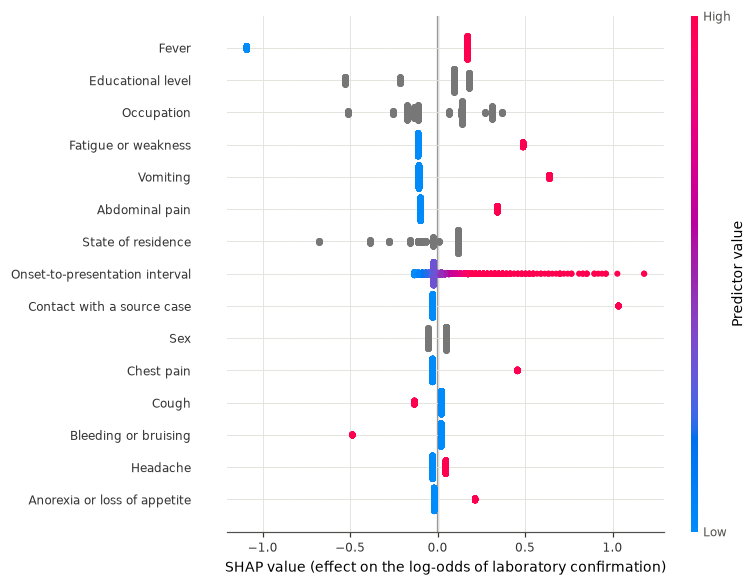

  saved figures/fig_shap_logistic_regression.png


In [24]:
def shap_beeswarm(S, V, fname, max_display=15):
    """Beeswarm at the level of the source variable; categorical variables are drawn in grey."""
    fig = plt.figure(figsize=(7.2, 5.4))
    shap.summary_plot(S.to_numpy(), V.to_numpy(), feature_names=[LABELS[c] for c in S.columns],
                      show=False, max_display=max_display, plot_size=None,
                      color_bar_label="Predictor value")
    ax = fig.axes[0]
    ax.set_xlabel("SHAP value (effect on the log-odds of laboratory confirmation)", fontsize=9)
    ax.tick_params(axis="both", labelsize=8)
    for extra in fig.axes[1:]:
        extra.tick_params(labelsize=8); extra.set_ylabel("Predictor value", fontsize=9)
    savefig(fname)

shap_beeswarm(S_lr, V_lr, "fig_shap_logistic_regression")

## 15. Out-of-sample predictive importance (held-out test set)

Permutation importance of the selected model on the whole test set: the mean decrease in ROC-AUC
when one predictor is shuffled, over 30 repeats. Unlike section 9, this measures what the fitted
model actually relies on when predicting unseen cases.

  saved outputs/permutation_importance_test_set.csv  (51 rows)
                         label  importance     sd
                         Fever      0.0285 0.0066
                      Vomiting      0.0281 0.0040
           Fatigue or weakness      0.0196 0.0038
                Abdominal pain      0.0181 0.0032
             Educational level      0.0169 0.0043
    Contact with a source case      0.0138 0.0021
                    Occupation      0.0126 0.0027
                       Malaise      0.0063 0.0018
                    Chest pain      0.0047 0.0018
Onset-to-presentation interval      0.0040 0.0024
  Anorexia or loss of appetite      0.0027 0.0011
                      Jaundice      0.0020 0.0013
                   Muscle pain      0.0015 0.0009
                      Headache      0.0014 0.0006
                           Sex      0.0014 0.0009


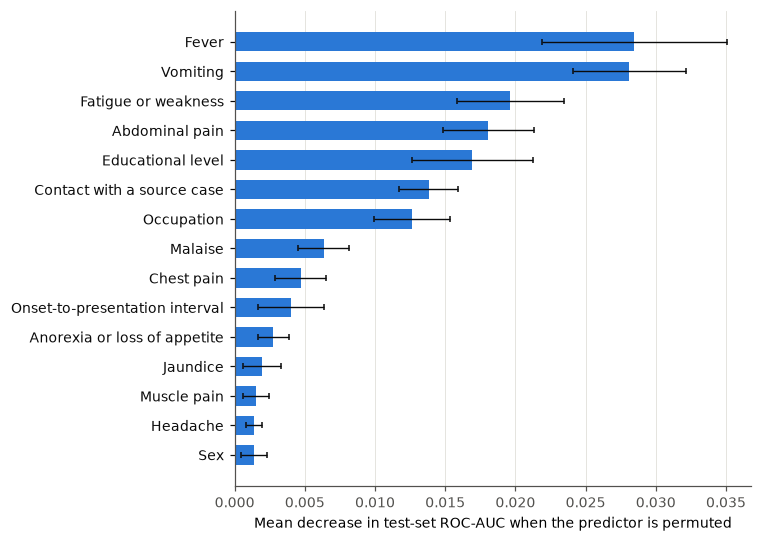

  saved figures/fig_permutation_importance_selected_model.png


In [25]:
from sklearn.inspection import permutation_importance

pi = permutation_importance(best, X_te, y_te, scoring="roc_auc", n_repeats=30,
                            random_state=RANDOM_STATE, n_jobs=N_JOBS)
pi_df = (pd.DataFrame({"variable": X_te.columns, "label": [LABELS[c] for c in X_te.columns],
                       "importance": pi.importances_mean, "sd": pi.importances_std})
         .sort_values("importance", ascending=False).reset_index(drop=True))
pi_df["rank"] = np.arange(1, len(pi_df) + 1)
save_table(pi_df, "permutation_importance_test_set")
print(pi_df.head(15)[["label", "importance", "sd"]].round(4).to_string(index=False))

tk = pi_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(tk["label"], tk["importance"], xerr=tk["sd"], color=BLUE, height=0.65,
        error_kw={"elinewidth": 0.9, "capsize": 2, "ecolor": INK})
ax.set_xlabel("Mean decrease in test-set ROC-AUC when the predictor is permuted")
ax.grid(axis="y", visible=False); ax.tick_params(axis="y", colors=INK)
savefig("fig_permutation_importance_selected_model")

  saved outputs/shap_xgboost_by_variable.csv  (51 rows)


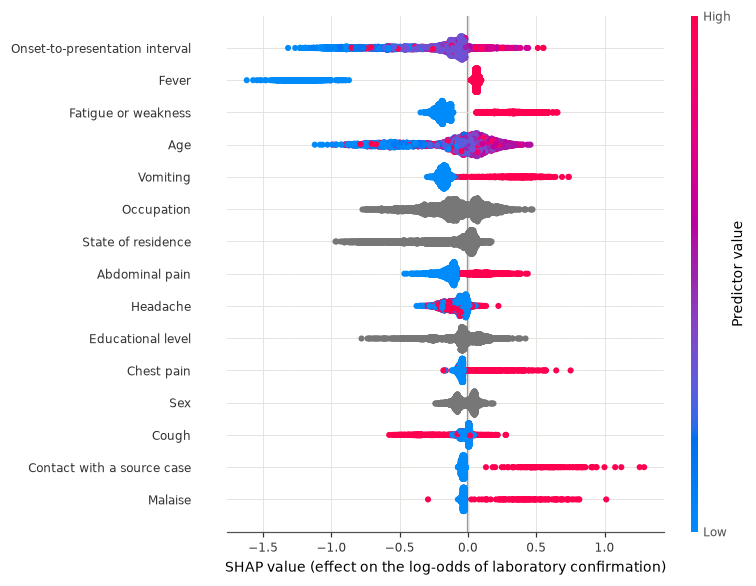

  saved figures/fig_shap_xgboost.png
  saved outputs/importance_rankings.csv  (51 rows)
  saved outputs/importance_rank_agreement.csv  (5 rows)
                  measure_a                   measure_b  n_predictors  spearman  top10_shared
   shap_logistic_regression permutation_importance_test            51     0.577             8
   shap_logistic_regression                shap_xgboost            51     0.851             8
permutation_importance_test                shap_xgboost            51     0.546             7
           anova_F_training permutation_importance_test            47     0.501             6
           anova_F_training    shap_logistic_regression            47     0.694             4

Top 10 by each measure:
               anova_F_training     permutation_importance_test        shap_logistic_regression                    shap_xgboost
0           Fatigue or weakness                           Fever                           Fever  Onset-to-presentation interval
1          

In [26]:
# Secondary, non-linear check: SHAP for the XGBoost model, and agreement between the rankings
xgb_pipe = fitted["XGBoost"]; pre_x = xgb_pipe.named_steps["pre"]
names_x = list(pre_x.get_feature_names_out()); Xte_x = to_dense(pre_x.transform(X_te))
sv_x = shap.TreeExplainer(xgb_pipe.named_steps["clf"]).shap_values(Xte_x)
sv_x = sv_x[1] if isinstance(sv_x, list) else (sv_x[..., 1] if getattr(sv_x, "ndim", 2) == 3 else sv_x)
S_x, V_x = by_variable(sv_x, Xte_x, names_x)
shap_x = aggregate_shap(S_x); shap_x["rank"] = np.arange(1, len(shap_x) + 1)
save_table(shap_x, "shap_xgboost_by_variable")
shap_beeswarm(S_x, V_x, "fig_shap_xgboost")

assoc_var = assoc[assoc["kind"] != "categorical level"].set_index("feature")["anova_F"]
rank = pd.DataFrame({
    "label": pd.Series(LABELS),
    "anova_F_training": assoc_var,
    "permutation_importance_test": pi_df.set_index("variable")["importance"],
    "shap_logistic_regression": shap_lr.set_index("variable")["mean_abs_shap"],
    "shap_xgboost": shap_x.set_index("variable")["mean_abs_shap"],
}).loc[feature_cols]
for c in ["anova_F_training", "permutation_importance_test", "shap_logistic_regression", "shap_xgboost"]:
    rank["rank_" + c] = rank[c].rank(ascending=False)
save_table(rank.rename_axis("variable").reset_index(), "importance_rankings")

def agree(a, b, k=10):
    sub = rank[[a, b]].dropna()
    return {"measure_a": a, "measure_b": b, "n_predictors": len(sub),
            "spearman": stats.spearmanr(sub[a], sub[b])[0],
            f"top{k}_shared": len(set(sub[a].nlargest(k).index) & set(sub[b].nlargest(k).index))}
pairs = [("shap_logistic_regression", "permutation_importance_test"),
         ("shap_logistic_regression", "shap_xgboost"),
         ("permutation_importance_test", "shap_xgboost"),
         ("anova_F_training", "permutation_importance_test"),
         ("anova_F_training", "shap_logistic_regression")]
agreement = pd.DataFrame([agree(a, b) for a, b in pairs])
save_table(agreement, "importance_rank_agreement")
print(agreement.round(3).to_string(index=False))
print("\nTop 10 by each measure:")
print(pd.DataFrame({c: rank[c].nlargest(10).index.map(LABELS) for c in
                    ["anova_F_training", "permutation_importance_test",
                     "shap_logistic_regression", "shap_xgboost"]}).to_string())

## 16. Sensitivity of performance to the handling of missing data

Five analyses, each run for all nine models with the same folds and the same test set:

- **A. Primary**: "Unknown" and blank both imputed, no missingness indicators.
- **B. Indicators added**: as A, plus one 0/1 indicator per predictor that has unavailable values.
- **C. High-missingness predictors excluded**: predictors unavailable in more than 40% of
  training records are removed.
- **D. Unknown kept apart from blank**: as A, plus separate indicators for an explicit
  "Unknown" answer and for a blank field.
- **E. Indicators only**: the indicators from B and nothing else, to measure how much the
  pattern of documentation predicts the outcome on its own.

In [27]:
HIGH_MISSING = 40.0
miss_cols = [c for c in feature_cols if X_tr[c].isna().any()]
IND = X[miss_cols].isna().astype(int).add_prefix("miss__")
unk_cols = [c for c in bin_cols if (status.loc[X_tr.index, c] == "unknown").any()]
UNK = (status[unk_cols] == "unknown").astype(int).add_prefix("unk__")
BLK = pd.DataFrame({f"blank__{c}": (status[c] == "blank").astype(int) if c in bin_cols
                    else X[c].isna().astype(int) for c in miss_cols})
BLK = BLK.loc[:, BLK.loc[X_tr.index].sum() > 0]
high = [c for c in feature_cols if 100 * X_tr[c].isna().mean() > HIGH_MISSING]
print(f"Predictors with unavailable values in the training set: {len(miss_cols)}")
print(f"Binary predictors with explicit 'Unknown' answers: {len(unk_cols)}")
print(f"Excluded in analysis C (> {HIGH_MISSING:.0f}% unavailable):", [LABELS[c] for c in high])

keep_c = [c for c in feature_cols if c not in high]
VARIANTS = {
    "A. Primary (imputation only)": (X, make_preprocessor(num_cols, bin_cols, cat_cols)),
    "B. Missingness indicators added": (
        pd.concat([X, IND], axis=1), make_preprocessor(num_cols, bin_cols, cat_cols, IND.columns)),
    "C. High-missingness predictors excluded": (
        X[keep_c], make_preprocessor([c for c in num_cols if c in keep_c],
                                     [c for c in bin_cols if c in keep_c],
                                     [c for c in cat_cols if c in keep_c])),
    "D. Unknown kept apart from blank": (
        pd.concat([X, UNK, BLK], axis=1),
        make_preprocessor(num_cols, bin_cols, cat_cols, list(UNK.columns) + list(BLK.columns))),
    "E. Missingness indicators only": (IND, make_preprocessor([], [], [], IND.columns)),
}

sens_rows, sens_P = [], {}
for vname, (Xv, pre_v) in VARIANTS.items():
    print(f"\n{vname}: {Xv.shape[1]} input columns")
    if vname.startswith("A."):
        cv_v, P_v = cv_df, P_te
    else:
        cv_v, _ = cv_evaluate(all_models, Xv.loc[X_tr.index], y_tr, pre_v, verbose=False)
        fit_v = fit_all(all_models, Xv.loc[X_tr.index], y_tr, pre_v)
        P_v = pd.DataFrame({n: proba(p, Xv.loc[X_te.index]) for n, p in fit_v.items()}, index=X_te.index)
    sens_P[vname] = P_v
    for name in cv_df["model"]:
        c = cv_v.set_index("model").loc[name]; t = all_metrics(yt_arr, P_v[name].to_numpy())
        row = {"analysis": vname, "model": name, "n_columns": Xv.shape[1]}
        for k in ["roc_auc", "pr_auc", "balanced_accuracy", "f1", "recall"]:
            row["cv_" + k] = c[k]; row["cv_" + k + "_ci95"] = c[k + "_ci95"]
        for k in ["roc_auc", "average_precision", "balanced_accuracy", "f1", "recall", "brier"]:
            row["test_" + k] = t[k]
        pv, pa = P_v[name].to_numpy(), P_te[name].to_numpy()
        d = np.array([roc_auc_score(yt_arr[i], pv[i]) - roc_auc_score(yt_arr[i], pa[i]) for i in boot_idx])
        row["test_roc_auc_diff_vs_primary"] = t["roc_auc"] - roc_auc_score(yt_arr, pa)
        row["test_roc_auc_diff_lo"], row["test_roc_auc_diff_hi"] = np.percentile(d, [2.5, 97.5])
        b = np.array([roc_auc_score(yt_arr[i], pv[i]) for i in boot_idx])
        row["test_roc_auc_lo"], row["test_roc_auc_hi"] = np.percentile(b, [2.5, 97.5])
        sens_rows.append(row)
    print(pd.DataFrame([r for r in sens_rows if r["analysis"] == vname])
          [["model", "cv_roc_auc", "cv_balanced_accuracy", "cv_f1", "test_roc_auc",
            "test_roc_auc_diff_vs_primary"]].round(3).to_string(index=False))

sens = pd.DataFrame(sens_rows)
save_table(sens, "missingness_sensitivity")

Predictors with unavailable values in the training set: 48
Binary predictors with explicit 'Unknown' answers: 42
Excluded in analysis C (> 40% unavailable): ['Contact with a source case', 'Direct contact with a probable case', 'Contact with rodents or their excreta', 'Pregnancy', 'Onset-to-presentation interval']

A. Primary (imputation only): 51 input columns


              model  cv_roc_auc  cv_balanced_accuracy  cv_f1  test_roc_auc  test_roc_auc_diff_vs_primary
             LogReg       0.704                 0.652  0.377         0.699                           0.0
     SVM(LinearSVC)       0.702                 0.650  0.375         0.698                           0.0
SoftVote(LR+RF+XGB)       0.719                 0.614  0.358         0.709                           0.0
                KNN       0.633                 0.607  0.330         0.622                           0.0
             HistGB       0.703                 0.590  0.305         0.692                           0.0
Stacking(RF+XGB+LR)       0.703                 0.588  0.304         0.695                           0.0
                MLP       0.608                 0.586  0.304         0.612                           0.0
            XGBoost       0.698                 0.575  0.268         0.683                           0.0
       RandomForest       0.691                 0.575  

              model  cv_roc_auc  cv_balanced_accuracy  cv_f1  test_roc_auc  test_roc_auc_diff_vs_primary
             LogReg       0.711                 0.652  0.376         0.703                         0.004
     SVM(LinearSVC)       0.710                 0.651  0.375         0.700                         0.002
SoftVote(LR+RF+XGB)       0.737                 0.620  0.370         0.729                         0.019
                KNN       0.645                 0.608  0.331         0.651                         0.028
             HistGB       0.723                 0.592  0.311         0.716                         0.024
Stacking(RF+XGB+LR)       0.715                 0.596  0.319         0.705                         0.010
                MLP       0.636                 0.599  0.323         0.625                         0.013
            XGBoost       0.722                 0.583  0.286         0.718                         0.035
       RandomForest       0.718                 0.581  

              model  cv_roc_auc  cv_balanced_accuracy  cv_f1  test_roc_auc  test_roc_auc_diff_vs_primary
             LogReg       0.695                 0.643  0.368         0.685                        -0.014
     SVM(LinearSVC)       0.693                 0.641  0.366         0.684                        -0.014
SoftVote(LR+RF+XGB)       0.697                 0.607  0.342         0.682                        -0.027
                KNN       0.631                 0.596  0.319         0.609                        -0.013
             HistGB       0.673                 0.579  0.280         0.664                        -0.028
Stacking(RF+XGB+LR)       0.684                 0.590  0.308         0.672                        -0.024
                MLP       0.586                 0.576  0.289         0.586                        -0.026
            XGBoost       0.670                 0.567  0.247         0.652                        -0.031
       RandomForest       0.668                 0.570  

              model  cv_roc_auc  cv_balanced_accuracy  cv_f1  test_roc_auc  test_roc_auc_diff_vs_primary
             LogReg       0.711                 0.652  0.377         0.702                         0.003
     SVM(LinearSVC)       0.709                 0.651  0.376         0.701                         0.003
SoftVote(LR+RF+XGB)       0.735                 0.618  0.366         0.727                         0.018
                KNN       0.645                 0.605  0.327         0.649                         0.027
             HistGB       0.725                 0.590  0.306         0.715                         0.023
Stacking(RF+XGB+LR)       0.711                 0.592  0.312         0.707                         0.012
                MLP       0.633                 0.595  0.317         0.621                         0.009
            XGBoost       0.722                 0.584  0.289         0.719                         0.036
       RandomForest       0.714                 0.581  

              model  cv_roc_auc  cv_balanced_accuracy  cv_f1  test_roc_auc  test_roc_auc_diff_vs_primary
             LogReg       0.587                 0.561  0.290         0.580                        -0.119
     SVM(LinearSVC)       0.586                 0.561  0.290         0.579                        -0.119
SoftVote(LR+RF+XGB)       0.611                 0.571  0.299         0.597                        -0.113
                KNN       0.560                 0.549  0.275         0.539                        -0.083
             HistGB       0.608                 0.564  0.294         0.607                        -0.084
Stacking(RF+XGB+LR)       0.609                 0.565  0.294         0.603                        -0.092
                MLP       0.611                 0.572  0.297         0.612                         0.001
            XGBoost       0.608                 0.563  0.294         0.605                        -0.079
       RandomForest       0.608                 0.563  

Selected model (LogReg) across the five analyses:
analysis                      A. Primary (imputation only)  B. Missingness indicators added  C. High-missingness predictors excluded  D. Unknown kept apart from blank  E. Missingness indicators only
n_columns                                               51                               99                                       46                               141                              48
cv_roc_auc                                           0.704                            0.711                                    0.695                             0.711                           0.587
cv_roc_auc_ci95                                      0.022                            0.021                                    0.022                             0.019                           0.016
cv_balanced_accuracy                                 0.652                            0.652                                    0.643                      

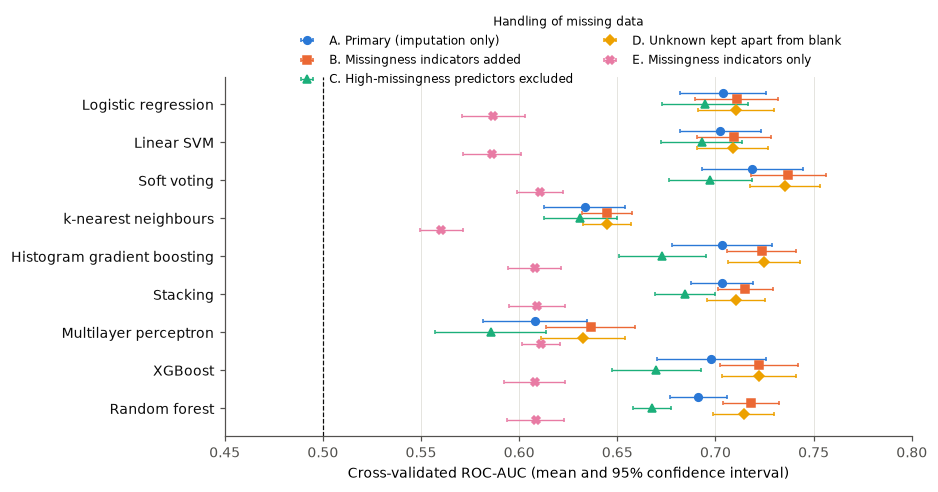

  saved figures/fig_missingness_sensitivity.png


In [28]:
sel = sens[sens["model"] == best_name]
print(f"Selected model ({best_name}) across the five analyses:")
print(sel[["analysis", "n_columns", "cv_roc_auc", "cv_roc_auc_ci95", "cv_balanced_accuracy", "cv_f1",
           "cv_recall", "test_roc_auc", "test_roc_auc_lo", "test_roc_auc_hi",
           "test_roc_auc_diff_vs_primary", "test_roc_auc_diff_lo", "test_roc_auc_diff_hi",
           "test_average_precision", "test_balanced_accuracy", "test_f1"]].round(3).T.to_string(header=False))
print("\nRange of cross-validated ROC-AUC over the nine models, by analysis:")
print(sens.groupby("analysis")["cv_roc_auc"].agg(["min", "median", "max"]).round(3).to_string())

fig, ax = plt.subplots(figsize=(8.6, 4.6))
analyses = list(VARIANTS); cols = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]; marks = ["o", "s", "^", "D", "X"]
ypos = np.arange(len(cv_df))[::-1]
for i, (a, col, mk) in enumerate(zip(analyses, cols, marks)):
    s = sens[sens["analysis"] == a].set_index("model").loc[cv_df["model"]]
    ax.errorbar(s["cv_roc_auc"], ypos + (2 - i) * 0.15, xerr=s["cv_roc_auc_ci95"], fmt=mk, color=col,
                ms=5, elinewidth=0.9, capsize=1.5, label=a)
ax.axvline(0.5, color=INK, ls="--", lw=0.8)
ax.set_yticks(ypos); ax.set_yticklabels([MODEL_NAMES[m] for m in cv_df["model"]], color=INK)
ax.set_xlabel("Cross-validated ROC-AUC (mean and 95% confidence interval)")
ax.set_xlim(0.45, 0.80); ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=2, title="Handling of missing data",
          title_fontsize=8)
savefig("fig_missingness_sensitivity")

### 16.1 Discrimination of the selected model by record completeness

If the model relied mainly on how completely a record was filled in, it would discriminate poorly
among records in which every symptom field was recorded. The primary model is therefore evaluated
separately in test records with all, some or none of the symptom fields recorded.

In [29]:
n_blank = (status[sym] == "blank").sum(axis=1)
completeness = pd.Series(np.select([n_blank == 0, n_blank == len(sym)],
                                   ["All symptom fields recorded", "All symptom fields blank"],
                                   "Some symptom fields blank"), index=X.index)
rows = []; rng_c = np.random.default_rng(RANDOM_STATE)
for lvl in ["All symptom fields recorded", "Some symptom fields blank", "All symptom fields blank"]:
    in_lvl = completeness == lvl
    idx = X_te.index[in_lvl.loc[X_te.index]]
    yy = y_te.loc[idx].to_numpy(); pp = P_te.loc[idx, best_name].to_numpy()
    row = {"stratum": lvl, "n_records": int(in_lvl.sum()), "pct_of_records": 100 * in_lvl.mean(),
           "pct_confirmed": 100 * y[in_lvl].mean(), "n_test": len(idx),
           "n_test_confirmed": int(yy.sum()), "mean_predicted_probability": pp.mean(),
           "recall_at_0.5": threshold_metrics(yy, pp)["recall"]}
    if len(idx) >= 50 and 0 < yy.sum() < len(yy):
        bs = []
        for _ in range(N_BOOT):
            i = rng_c.integers(0, len(yy), len(yy))
            if 0 < yy[i].sum() < len(i):
                bs.append(roc_auc_score(yy[i], pp[i]))
        row.update({"roc_auc": roc_auc_score(yy, pp), "roc_auc_lo": np.percentile(bs, 2.5),
                    "roc_auc_hi": np.percentile(bs, 97.5)})
    rows.append(row)
by_completeness = pd.DataFrame(rows)
save_table(by_completeness, "performance_by_record_completeness")
print(by_completeness.round(3).to_string(index=False))

  saved outputs/performance_by_record_completeness.csv  (3 rows)
                    stratum  n_records  pct_of_records  pct_confirmed  n_test  n_test_confirmed  mean_predicted_probability  recall_at_0.5  roc_auc  roc_auc_lo  roc_auc_hi
All symptom fields recorded      15919          79.488         17.344    3155               553                       0.471          0.631    0.702       0.678       0.728
  Some symptom fields blank        901           4.499          4.883     180                11                       0.174          0.000    0.484       0.281       0.695
   All symptom fields blank       3207          16.013         11.132     671                68                       0.417          0.221    0.604       0.538       0.669


## 17. Subgroup discrimination of the selected model

In [30]:
sub = []
rng_s = np.random.default_rng(RANDOM_STATE)
for col, title in [(SEX_COL, "Sex"), (STATE_COL, "State of residence")]:
    g = df.loc[X_te.index, col]
    for lvl in g.dropna().unique():
        idx = g.index[g == lvl]
        if len(idx) < 50 or y_te.loc[idx].nunique() < 2:
            continue
        yy = y_te.loc[idx].to_numpy(); pp = P_te.loc[idx, best_name].to_numpy()
        bs = []
        for _ in range(N_BOOT):
            i = rng_s.integers(0, len(yy), len(yy))
            if 0 < yy[i].sum() < len(i):
                bs.append(roc_auc_score(yy[i], pp[i]))
        name = SEX_NAMES.get(lvl, lvl) if col == SEX_COL else lvl
        sub.append({"variable": title, "group": name, "n": len(idx), "n_confirmed": int(yy.sum()),
                    "roc_auc": roc_auc_score(yy, pp), "roc_auc_lo": np.percentile(bs, 2.5),
                    "roc_auc_hi": np.percentile(bs, 97.5)})
    print(f"{title}: test records without a recorded value = {int(g.isna().sum())}")
sub_df = pd.DataFrame(sub).sort_values(["variable", "n"], ascending=[True, False]).reset_index(drop=True)
save_table(sub_df, "subgroup_auc")
print(sub_df.round(3).to_string(index=False))

Sex: test records without a recorded value = 82


State of residence: test records without a recorded value = 418
  saved outputs/subgroup_auc.csv  (9 rows)
          variable   group    n  n_confirmed  roc_auc  roc_auc_lo  roc_auc_hi
               Sex    male 2063          338    0.709       0.679       0.739
               Sex  female 1861          282    0.684       0.648       0.721
State of residence     Edo 1836          285    0.690       0.657       0.725
State of residence    Ondo  805          121    0.717       0.665       0.767
State of residence  Ebonyi  233           37    0.719       0.627       0.803
State of residence  Bauchi  157           37    0.718       0.613       0.814
State of residence   Delta   87           14    0.875       0.757       0.963
State of residence  Taraba   66            9    0.762       0.608       0.911
State of residence Plateau   63           10    0.587       0.369       0.790


## 18. Summary

In [31]:
cv_df.to_csv(OUT_DIR / "model_comparison_summary.csv", index=False)
print("Cross-validation (training set), ordered by balanced accuracy:")
print(cv_df[["model"] + list(SCORING)].round(3).to_string(index=False))
print("\nHeld-out test set:")
print(test_df[["model"] + CI_METRICS].round(3).to_string(index=False))
print("\nAll tables -> outputs/   All figures -> figures/")

Cross-validation (training set), ordered by balanced accuracy:
              model  accuracy  balanced_accuracy  precision  recall    f1  roc_auc  pr_auc
             LogReg     0.688              0.652      0.276   0.599 0.377    0.704   0.354
     SVM(LinearSVC)     0.685              0.650      0.273   0.600 0.375    0.702   0.351
SoftVote(LR+RF+XGB)     0.830              0.614      0.445   0.299 0.358    0.719   0.384
                KNN     0.681              0.607      0.247   0.499 0.330    0.633   0.239
             HistGB     0.845              0.590      0.523   0.216 0.305    0.703   0.363
Stacking(RF+XGB+LR)     0.815              0.588      0.375   0.256 0.304    0.703   0.305
                MLP     0.743              0.586      0.268   0.357 0.304    0.608   0.285
            XGBoost     0.848              0.575      0.555   0.177 0.268    0.698   0.363
       RandomForest     0.818              0.575      0.370   0.219 0.275    0.691   0.285

Held-out test set:
       